# 3.1 — La rétropropagation : la chaîne des gradients à la main

**Navigation** : [<< 2.2-Descente-de-gradient](../02-ML-Cours/2.2-Descente-de-gradient.ipynb) | [2.9-Grokking (épilogue du socle ML)](../02-ML-Cours/2.9-Grokking-Generalisation.ipynb) | [Index](README.md) | [3.2 — Les optimisateurs >>](3.2-Optimisateurs.ipynb)

**Kernel** : Python (NumPy pur + comparaison PyTorch) · **CPU** : oui · **Durée** : selon la machine

***

## Introduction

Le socle [`02-ML-Cours`](../02-ML-Cours/README.md) s'arrête sur un paradoxe. D'un côté, `2.2` a
ouvert la boîte noire de `fit()` — mais pour **une droite** : un modèle à deux paramètres, un
gradient qui s'écrit sur une ligne. De l'autre, `2.9` a entraîné un vrai réseau de neurones
(PyTorch) pour montrer le grokking — en le laissant entièrement **boîte noire** :
`loss.backward()` et l'entraînement suit. Entre les deux, le chaînon manquant : **comment le
gradient traverse-t-il les couches d'un réseau ?**

Ce notebook le construit à la main. Un petit perceptron multi-couches (MLP) en **NumPy pur,
sans autograd**, sur un problème 2D non séparable linéairement. La démarche en trois contrôles :

1. **le contrôle du calcul** : le gradient écrit à la main (chain rule couche par couche) est
   confronté au gradient numérique par différence finie — l'écart doit être nul à l'epsilon près ;
2. **la comparaison avec autograd** : la même architecture, les mêmes poids initiaux, le même pas
   de descente en PyTorch — écarts de perte et de trajectoire mesurés ;
3. **l’expérience d’initialisation nulle** : sur ce réseau ReLU et ce split équilibré, l’initialisation nulle laisse les poids cachés inactifs ; une initialisation asymétrique peut briser la symétrie.

Littérature fondatrice : Rumelhart, Hinton & Williams (1986), *Learning representations by
back-propagating errors* — l'article qui a generalisé la chain rule aux réseaux multi-couches.

**Objectifs** : dériver et vérifier les gradients, mesurer les entraînements et comparer à l’autograd. **Prérequis** : algèbre matricielle et dérivation. **Durée** : 2–3 heures. [Version C#](3.1-Retropropagation-CSharp.ipynb).


***

## 1. Le problème : une frontière courbe que la régression logistique ne peut pas tracer

Le jeu de données `make_moons` (déjà croisé en [2.7](../02-ML-Cours/2.7-Modeles-Non-Parametriques.ipynb))
compose deux demi-lunes imbriquées : aucune droite ne sépare les deux classes. C'est le terrain
où un modèle **linéaire** se heurte à sa frontière droite. Les réseaux et d’autres modèles non linéaires peuvent représenter des frontières courbes.

Regression logistique : train 0.871 | test 0.873
Reproductibilite : seed globale NumPy = 42


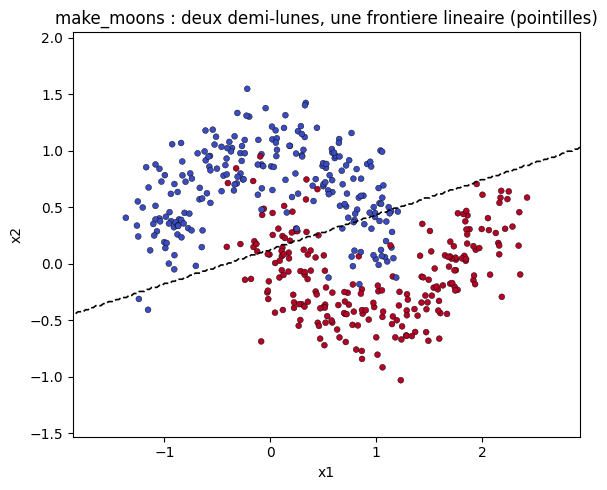

In [1]:
# Socle : donnees, baseline lineaire, visualisation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
rng = np.random.RandomState(SEED)

X, y = make_moons(n_samples=600, noise=0.20, random_state=SEED)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
Y_tr = np.eye(2)[y_tr]  # one-hot, la sortie du reseau sera une probabilite par classe

# Baseline : regression logistique (modele lineaire, deja vue en 2.3)
logreg = LogisticRegression().fit(X_tr, y_tr)
print(f"Regression logistique : train {logreg.score(X_tr, y_tr):.3f} | test {logreg.score(X_te, y_te):.3f}")
print(f"Reproductibilite : seed globale NumPy = {SEED}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="coolwarm", s=18, edgecolors="k", linewidths=0.3)
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
                     np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200))
Z = logreg.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0.5], colors="k", linestyles="--", linewidths=1.2)
ax.set_title("make_moons : deux demi-lunes, une frontiere lineaire (pointilles)")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout(); plt.show()

**Lecture.** La droite de décision de la régression logistique traverse les lunes en plein
milieu : **0,873** de précision test seulement. Cette régression logistique est linéaire —
aucune descente de gradient, aussi bien réglée soit-elle (cf 2.2), ne courbera cette droite. Un modèle non linéaire peut courber la frontière ; les réseaux ne sont pas les seuls à le faire.

***

## 2. Le MLP en NumPy pur : forward pass matricielle

Architecture minimale mais complète : **2 entrées → 32 neurones cachés (ReLU) → 2 sorties
(softmax)**. Tout est écrit en algèbre linéaire explicite — chaque couche est une matrice de
poids `W` et un vecteur de biais `b` :

$$Z^{(1)} = XW^{(1)} + b^{(1)}, \quad A^{(1)} = \mathrm{ReLU}(Z^{(1)}), \quad
Z^{(2)} = A^{(1)}W^{(2)} + b^{(2)}, \quad P = \mathrm{softmax}(Z^{(2)})$$

Le coût est l'entropie croisée moyenne : $L = -\frac{1}{n}\sum_i \log P_{i, y_i}$. L'init
**He** ($W \sim \mathcal{N}(0, \sqrt{2/n_{in}})$) est celle d'origine pour ReLU — le §7 montre
ce qui arrive sans elle.

In [2]:
# Le reseau : parametres He, forward pass explicite, cross-entropy
D, H, C = 2, 32, 2  # dimensions entree, cachee, sortie

def init_he(rng, D, H, C):
    return {"W1": rng.randn(D, H) * np.sqrt(2.0 / D), "b1": np.zeros(H),
            "W2": rng.randn(H, C) * np.sqrt(2.0 / H), "b2": np.zeros(C)}

def softmax(Z):
    Zs = Z - Z.max(axis=1, keepdims=True)  # stabilite numerique
    E = np.exp(Zs)
    return E / E.sum(axis=1, keepdims=True)

def relu(Z):
    return np.maximum(Z, 0.0)

def forward(params, X):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = relu(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    P = softmax(Z2)
    return {"Z1": Z1, "A1": A1, "Z2": Z2, "P": P}

def ce_logits(Z, Y):
    shifted = Z - Z.max(axis=1, keepdims=True)
    return np.mean(np.log(np.exp(shifted).sum(axis=1)) - shifted[np.arange(len(Y)), Y.argmax(axis=1)])

def loss_ce(params, X, Y):
    return ce_logits(forward(params, X)["Z2"], Y)

params0 = init_he(rng, D, H, C)
out0 = forward(params0, X_tr[:5])
print(f"Poids : W1 {params0['W1'].shape}, b1 {params0['b1'].shape}, "
      f"W2 {params0['W2'].shape}, b2 {params0['b2'].shape}")
print(f"Forward sur 5 exemples -> P de shape {out0['P'].shape}, lignes sommant a "
      f"{out0['P'].sum(axis=1)[:3]}")
print(f"Loss initiale (avant tout apprentissage) : {loss_ce(params0, X_tr, Y_tr):.4f}")
# Logits extrêmes : aucune multiplication 0 × log(0).
extreme = {"W1": np.zeros((2, 1)), "b1": np.zeros(1), "W2": np.zeros((1, 2)), "b2": np.array([1000., -1000.])}
assert np.isclose(loss_ce(extreme, np.zeros((1, 2)), np.array([[1., 0.]])), 0.)
assert np.isclose(loss_ce(extreme, np.zeros((1, 2)), np.array([[0., 1.]])), 2000.)
extreme["b2"] = np.array([1e20, 1e20])
assert np.isclose(loss_ce(extreme, np.zeros((1, 2)), np.array([[1., 0.]])), np.log(2), atol=1e-15)
extreme["b2"] = np.array([1e308, -1e308])
with np.errstate(over="ignore"):  # l’écart mathématique dépasse la plage float64
    assert loss_ce(extreme, np.zeros((1, 2)), np.array([[1., 0.]])) == 0.
print("Logits extrêmes : pertes 0, 2000 et ln(2) sous décalage commun ; classe maximale ±1e308 : 0")


Poids : W1 (2, 32), b1 (32,), W2 (32, 2), b2 (2,)
Forward sur 5 exemples -> P de shape (5, 2), lignes sommant a [1. 1. 1.]
Loss initiale (avant tout apprentissage) : 0.6165
Logits extrêmes : pertes 0, 2000 et ln(2) sous décalage commun ; classe maximale ±1e308 : 0


**Lecture.** Le forward est une chaîne de produits matriciels et d'élément-wise : **0,6165** de
loss initiale, sous $\ln 2 \approx 0{,}693$ (l'entropie d'une pièce équilibrée) — l'init He
donne déjà un léger penchant, le réseau n'est pas tout à fait indécis avant d'apprendre. Tout
l'apprentissage tient dans la question suivante : **comment chaque poids a-t-il influencé cette
loss ?** C'est exactement ce que `loss.backward()` de PyTorch calcule — et que nous allons
écrire.

***

## 3. Backward pass à la main : la chain rule couche par couche

Le principe : la dérivée de $L$ par rapport à un poids profond est un **produit de dérivées
locales** le long du chemin qui relie la sortie à ce poids. Pour la couche de sortie avec
softmax + entropie croisée, les deux se simplifient remarquablement :

$$\frac{\partial L}{\partial Z^{(2)}} = \frac{1}{n}\left(P - Y\right)$$

Puis on remonte : chaque couche cachee propage le gradient d'aval via $W$ et multiplie par la
dérivée locale de sa fonction d'activation ($\mathrm{ReLU}'(z) = \mathbb{1}[z > 0]$) :

$$\frac{\partial L}{\partial W^{(2)}} = A^{(1)\top}\delta^{(2)}, \quad
\delta^{(1)} = \left(\delta^{(2)}W^{(2)\top}\right) \odot \mathrm{ReLU}'(Z^{(1)}), \quad
\frac{\partial L}{\partial W^{(1)}} = X^\top\delta^{(1)}$$

avec $\delta^{(\ell)} = \frac{\partial L}{\partial Z^{(\ell)}}$. C'est le **théorème de
différentiation en chaîne appliqué à un graphe** : coûte un seul forward + un backward, quel que
soit le nombre de couches.

In [3]:
# Backward pass : les quatre gradients, ecrits a la main
def backward(params, X, Y):
    fwd = forward(params, X)
    n = X.shape[0]
    dZ2 = (fwd["P"] - Y) / n                      # softmax + CE combines
    dW2 = fwd["A1"].T @ dZ2
    db2 = dZ2.sum(axis=0)
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (fwd["Z1"] > 0)                   # ReLU'(z) = 1 si z > 0, sinon 0
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

grads0 = backward(params0, X_tr, Y_tr)
for k in ("W1", "b1", "W2", "b2"):
    print(f"grad {k} : shape {grads0[k].shape}, norme {np.linalg.norm(grads0[k]):.6f}")

grad W1 : shape (2, 32), norme 0.238159
grad b1 : shape (32,), norme 0.183066
grad W2 : shape (32, 2), norme 1.123216
grad b2 : shape (2,), norme 0.028924


***

## 4. Le contrôle du calcul : gradient numérique par différence finie

Écrire le backward à la main, c'est facile de se tromper d'un signe ou d'une transposée. La
vérification canonique : approcher chaque dérivée partielle par **différence centrale**
$\frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon}$ et comparer au
gradient analytique, **paramètre par paramètre**, sur les quatre tenseurs. Sur ces 20 exemples, on compare l’écart au seuil pratique $10^{-6}$ avec $\varepsilon=10^{-5}$. Le contrôle est local et peut être perturbé au voisinage d’un angle ReLU.

In [4]:
# Verification : gradient numerique (differences centrales) vs analytique
def num_grad_check(params, X, Y, eps=1e-5):
    grads = backward(params, X, Y)
    report = {}
    for name in ("W1", "b1", "W2", "b2"):
        theta = params[name]
        g_num = np.zeros_like(theta)
        it = np.nditer(theta, flags=["multi_index"])
        while not it.finished:
            idx = it.multi_index
            orig = theta[idx]
            theta[idx] = orig + eps; lp = loss_ce(params, X, Y)
            theta[idx] = orig - eps; lm = loss_ce(params, X, Y)
            theta[idx] = orig
            g_num[idx] = (lp - lm) / (2 * eps)
            it.iternext()
        report[name] = np.abs(grads[name] - g_num).max()
    return report

X_chk, Y_chk = X_tr[:20], Y_tr[:20]  # sous-echantillon : le cout est 2 forwards par parametre
check = num_grad_check(params0, X_chk, Y_chk)
for name, err in check.items():
    verdict = "OK" if err < 1e-6 else "BUG"
    print(f"{name} : ecart max |analytique - numerique| = {err:.3e}  [{verdict}]")
print(f"Ecart max global : {max(check.values()):.3e} (seuil 1e-6)")

W1 : ecart max |analytique - numerique| = 1.096e-11  [OK]
b1 : ecart max |analytique - numerique| = 8.998e-12  [OK]
W2 : ecart max |analytique - numerique| = 1.135e-11  [OK]
b2 : ecart max |analytique - numerique| = 1.189e-11  [OK]
Ecart max global : 1.189e-11 (seuil 1e-6)


**Lecture.** Les quatre tenseurs passent : écart max **1,2 × 10⁻¹¹**, cinq ordres de grandeur
sous le seuil de 10⁻⁶ — le backward concorde avec les différences finies sur ce petit échantillon, loin des points non différentiables de ReLU. Ce garde-fou est le réflexe à garder à vie : avant d'entraîner (ou de debuguer) un réseau,
on vérifie le gradient. C'est aussi ce que fait PyTorch en interne quand il teste `gradcheck` —
la même méthode, appliquée à l'autograd.

***

## 5. Boucle d'entraînement : le réseau résout ce que la droite ne pouvait pas

Il ne reste qu'à boucler : descente de gradient **pure** (le régime de 2.2 — momentum et Adam
sont le sujet de [3.2](./3.2-Optimisateurs.ipynb), pas d'ici), 3000 itérations full-batch, un learning rate
modeste. À chaque pas : forward, backward, mise à jour $\theta \leftarrow \theta -
\eta \nabla L$.

Budget zéro : paramètres inchangés


Loss : 0.6165 -> 0.1054
Accuracy train 0.967 | test 0.967


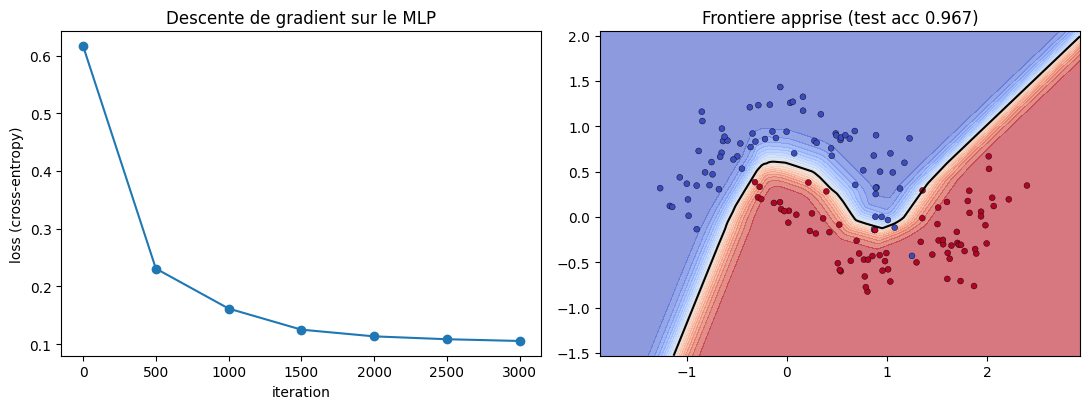

In [5]:
# Entrainement : descente de gradient pure, 3000 iterations full-batch
def accuracy(params, X, y):
    return (forward(params, X)["P"].argmax(axis=1) == y).mean()

def train_numpy(params, X, Y, y, lr=0.1, iters=3000, log_every=500):
    history = []
    for it in range(iters + 1):
        if it % log_every == 0:
            history.append((it, loss_ce(params, X, Y)))
        if it == iters:
            break  # le checkpoint final décrit les paramètres après exactement iters mises à jour
        g = backward(params, X, Y)
        for k in params:
            params[k] -= lr * g[k]
    return history

_zero_step = init_he(np.random.RandomState(SEED), D, H, C)
_before = {k: v.copy() for k,v in _zero_step.items()}
train_numpy(_zero_step, X_tr, Y_tr, y_tr, iters=0)
assert all(np.array_equal(_zero_step[k], _before[k]) for k in _before)
print("Budget zéro : paramètres inchangés")
params = init_he(np.random.RandomState(SEED), D, H, C)
hist = train_numpy(params, X_tr, Y_tr, y_tr, lr=0.1, iters=3000)
print(f"Loss : {hist[0][1]:.4f} -> {hist[-1][1]:.4f}")
print(f"Accuracy train {accuracy(params, X_tr, y_tr):.3f} | test {accuracy(params, X_te, y_te):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
its, losses = zip(*hist)
axes[0].plot(its, losses, "o-", color="tab:blue")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("loss (cross-entropy)")
axes[0].set_title("Descente de gradient sur le MLP")
Znet = forward(params, np.c_[xx.ravel(), yy.ravel()])["P"][:, 1].reshape(xx.shape)
axes[1].contourf(xx, yy, Znet, levels=20, cmap="coolwarm", alpha=0.6)
axes[1].contour(xx, yy, Znet, levels=[0.5], colors="k", linewidths=1.5)
axes[1].scatter(X_te[:, 0], X_te[:, 1], c=y_te, cmap="coolwarm", s=18, edgecolors="k", linewidths=0.3)
axes[1].set_title(f"Frontiere apprise (test acc {accuracy(params, X_te, y_te):.3f})")
plt.tight_layout(); plt.show()

**Lecture.** Le réseau fait ce que la droite ne pouvait pas : loss **0,6165 → 0,105**,
précision test **0,967** contre **0,873** pour la régression logistique. La frontière de
décision est courbe, épouse les demi-lunes. Et la courbe de loss ressemble à celle de 2.2 —
même régime de descente, seul le modèle a changé de richesse. La question qui brûle : **est-ce
bien la même mécanique que `torch.optim.SGD` ?** Vérifions-le plutôt que de le croire.

## Exercice 1 : tanh au lieu de ReLU — la dérivée locale change

Remplacez l'activation cachée par `tanh` (dérivée locale $1 - \tanh^2(z)$, qui ne s'annule pas
brutalement). Recopiez `forward`/`backward` en `forward_tanh`/`backward_tanh` (seuls `A1` et
`dZ1` changent), relancez le grad-check de la section 4 puis l'entraînement : l'initialisation
adaptée à tanh est **Xavier** ($\sqrt{1/n_{in}}$, pas $\sqrt{2/n_{in}}$).

Interface des stubs : `init_xavier`, `forward_tanh`, `backward_tanh` et `train_tanh` suivent les mêmes dictionnaires que le réseau principal. Les contrôles différencient la perte et vérifient la cohérence de l’entraînement retourné ; `train_tanh` renvoie (paramètres finaux, historique de loss).


In [6]:
# Exercice 1 : fournir initialisation Xavier, forward et backward tanh.
def init_xavier(rng, D, H, C):
    return None  # TODO

def forward_tanh(params, X):
    return None  # TODO : même contrat que forward

def backward_tanh(params, X, Y):
    return None  # TODO : quatre gradients

def train_tanh(params, X, Y, y, iters=3000, lr=0.1):
    return None  # TODO : (paramètres finaux, historique de loss)

p = init_xavier(np.random.RandomState(42), D, H, C)
if p is None:
    print("Exercice 1 à compléter")
else:
    try:
        f = forward_tanh(p, X_chk); g = backward_tanh(p, X_chk, Y_chk)
        valid = set(p) == set(g) == {"W1","b1","W2","b2"} and f["P"].shape == (20,2)
        valid &= 0.2 < np.std(p["W1"]) < 2 and 0.03 < np.std(p["W2"]) < 0.6 and np.allclose(p["b1"],0) and np.allclose(p["b2"],0)
        valid &= np.allclose(f["A1"],np.tanh(X_chk@p["W1"]+p["b1"]))
        valid &= np.allclose(f["Z2"],f["A1"]@p["W2"]+p["b2"]) and np.allclose(f["P"],softmax(f["Z2"]))
        def loss_tanh(q):
            z=forward_tanh(q,X_chk)["Z2"]; return ce_logits(z,Y_chk)
        for name in p:
            valid &= g[name].shape == p[name].shape and np.isfinite(g[name]).all()
            for idx in list(np.ndindex(p[name].shape))[:3]:
                old=p[name][idx]; p[name][idx]=old+1e-5; plus=loss_tanh(p); p[name][idx]=old-1e-5; minus=loss_tanh(p); p[name][idx]=old
                valid &= abs(g[name][idx]-(plus-minus)/2e-5)<1e-6
        valid &= np.isfinite(f["P"]).all() and np.allclose(f["P"].sum(axis=1),1)
        short = train_tanh({k:v.copy() for k,v in p.items()}, X_chk, Y_chk, y_tr[:20], iters=2)
        valid &= short is not None
        if short is not None:
            actual_short, _ = short; expected_short={k:v.copy() for k,v in p.items()}
            for _ in range(2):
                gs=backward_tanh(expected_short,X_chk,Y_chk)
                for k in expected_short: expected_short[k] -= 0.1*gs[k]
            valid &= all(np.allclose(actual_short[k],expected_short[k]) for k in expected_short)
        trained = train_tanh({k:v.copy() for k,v in p.items()}, X_tr, Y_tr, y_tr)
        valid &= trained is not None
        if trained is not None:
            final, history = trained
            z0=forward_tanh(p,X_tr)["Z2"];l0=ce_logits(z0,Y_tr)
            zf=forward_tanh(final,X_tr)["Z2"];lf=ce_logits(zf,Y_tr)
            valid &= len(history)>=2 and np.isfinite(history).all() and np.isclose(history[0],l0) and np.isclose(history[-1],lf) and history[-1] < history[0]
        print("Fixtures tanh validées" if valid else "Réponse incorrecte")
    except (TypeError, KeyError, ValueError, AttributeError): print("Réponse incorrecte")


Exercice 1 à compléter


***

## 6. La comparaison avec autograd : PyTorch, mêmes poids, même pas

Le même réseau en PyTorch — mêmes dimensions, **mêmes poids initiaux** (copiés depuis NumPy,
en float64 pour mesurer les écarts) — et trois mesures : la loss au premier forward, les
poids après un pas de descente, puis la trajectoire complète des 3000 itérations. Si nos maths
sont celles de PyTorch, on mesure les écarts.

PyTorch, logits décalés : 0.693147180560
Loss premier forward : NumPy 0.616485204453 | PyTorch 0.616485204453 | ecart 0.00e+00
Apres 1 pas : ecart max de poids NumPy vs PyTorch = 2.22e-16


Trajectoire 3000 iters : ecart max de loss NumPy vs PyTorch = 2.78e-17
Reproductibilite : seed globale PyTorch = 42


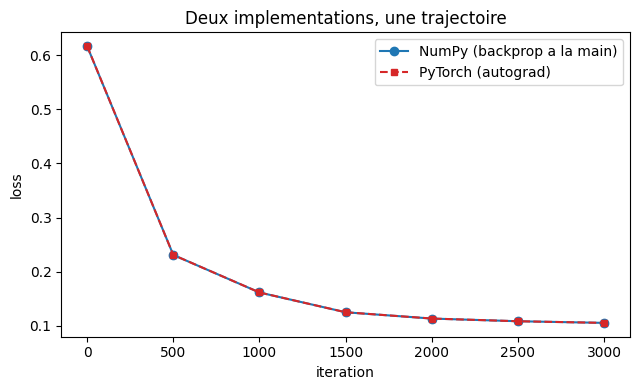

In [7]:
# Parite PyTorch : memes poids initiaux, un pas, puis 3000 iterations
import torch

torch.manual_seed(SEED)
_common = torch.tensor([[1e20, 1e20]], dtype=torch.float64)
_common_loss = torch.nn.functional.cross_entropy(_common, torch.tensor([0])).item()
assert np.isclose(_common_loss, np.log(2), atol=1e-15)
print(f"PyTorch, logits décalés : {_common_loss:.12f}")

def to_torch(params):
    return {"W1": torch.tensor(params["W1"], dtype=torch.float64, requires_grad=True),
            "b1": torch.tensor(params["b1"], dtype=torch.float64, requires_grad=True),
            "W2": torch.tensor(params["W2"], dtype=torch.float64, requires_grad=True),
            "b2": torch.tensor(params["b2"], dtype=torch.float64, requires_grad=True)}

def torch_forward_loss(tp, X_t, Y_t):
    Z1 = X_t @ tp["W1"] + tp["b1"]
    A1 = torch.relu(Z1)
    Z2 = A1 @ tp["W2"] + tp["b2"]
    return torch.nn.functional.cross_entropy(Z2, Y_t.argmax(dim=1)), Z1, A1

# -- memes poids de depart des deux cotes --
params_a = init_he(np.random.RandomState(SEED), D, H, C)
params_b = init_he(np.random.RandomState(SEED), D, H, C)
Xt = torch.tensor(X_tr, dtype=torch.float64); Yt = torch.tensor(Y_tr, dtype=torch.float64)

loss_np_before = loss_ce(params_a, X_tr, Y_tr)
tp = to_torch(params_b)
loss_t_before, _, _ = torch_forward_loss(tp, Xt, Yt)
print(f"Loss premier forward : NumPy {loss_np_before:.12f} | PyTorch {loss_t_before.item():.12f} "
      f"| ecart {abs(loss_np_before - loss_t_before.item()):.2e}")

# -- un pas de descente (eta = 0.1) des deux cotes --
g = backward(params_a, X_tr, Y_tr)
for k in params_a: params_a[k] -= 0.1 * g[k]
loss_t_before.backward()
with torch.no_grad():
    for k in tp: tp[k] -= 0.1 * tp[k].grad
dmax = max(np.abs(params_a[k] - tp[k].detach().numpy()).max() for k in params_a)
print(f"Apres 1 pas : ecart max de poids NumPy vs PyTorch = {dmax:.2e}")

# -- trajectoire complete 3000 iterations cote PyTorch (autograd) --
def train_torch(tp, iters=3000, lr=0.1, log_every=500):
    hist = []
    for it in range(iters + 1):
        loss, _, _ = torch_forward_loss(tp, Xt, Yt)
        if it % log_every == 0: hist.append((it, loss.item()))
        if it == iters:
            break  # dernier checkpoint, aucune mise à jour supplémentaire
        loss.backward()
        with torch.no_grad():
            for k in tp: tp[k] -= lr * tp[k].grad
            for k in tp: tp[k].grad = None
    return hist

hist_t = train_torch(to_torch(init_he(np.random.RandomState(SEED), D, H, C)))
hist_n = train_numpy(init_he(np.random.RandomState(SEED), D, H, C), X_tr, Y_tr, y_tr)
gaps = [abs(a[1] - b[1]) for a, b in zip(hist_n, hist_t)]
print(f"Trajectoire 3000 iters : ecart max de loss NumPy vs PyTorch = {max(gaps):.2e}")
print(f"Reproductibilite : seed globale PyTorch = {SEED}")

plt.figure(figsize=(6.5, 4))
plt.plot(*zip(*hist_n), "o-", label="NumPy (backprop a la main)", color="tab:blue")
plt.plot(*zip(*hist_t), "s--", label="PyTorch (autograd)", color="tab:red", ms=5)
plt.xlabel("iteration"); plt.ylabel("loss"); plt.legend(); plt.title("Deux implementations, une trajectoire")
plt.tight_layout(); plt.show()

**Lecture.** Dans ce run, l’écart initial est nul à l’affichage, l’écart maximal des poids après un pas est de **2,22 × 10⁻¹⁶**, et l’écart maximal des sept checkpoints est de **2,78 × 10⁻¹⁷**. Les deux implémentations concordent sur cette expérience en float64 ; cela ne garantit pas une égalité bit à bit sur d’autres données, matériels ou formats.


## Exercice 2 : cercles concentriques et deuxième couche cachée

`make_circles` est plus hostile que les lunes (une classe encerclée par l'autre). Générez-le
avec `factor=0.4, noise=0.15, random_state=42`, puis étendez le réseau à **deux couches
cachées** (2 → 32 → 32 → 2) : il faut une nouvelle paire forward/backward pour la couche
intermédiaire — le motif du §3 se répète tel quel, c'est tout l'intérêt de la formulation
matricielle.

La fonction `entrainer_cercles` retourne `(paramètres_finaux, paramètres_initiaux, forward, backward, historique_de_loss)` ; le forward expose `Z3` et `P`. L’historique commence par la perte du modèle initial et finit par celle du modèle final, inférieure à ln(2).


In [8]:
# Exercice 2 : retourner paramètres, fonctions forward/backward et historique après apprentissage.
def entrainer_cercles():
    return None  # TODO : make_circles 600 et réseau 2→32→32→2

rep = entrainer_cercles()
if rep is None: print("Exercice 2 à compléter")
else:
    try:
        from sklearn.datasets import make_circles
        model, initial_model, fwd, bwd, history = rep
        xc,yc=make_circles(n_samples=600,factor=.4,noise=.15,random_state=42)
        xt,xv,yt,yv=train_test_split(xc,yc,test_size=.25,random_state=42,stratify=yc)
        yc_hot=np.eye(2)[yt]; out=fwd(model,xt[:20]); grads=bwd(model,xt[:20],yc_hot[:20])
        valid=set(model)==set(grads)=={"W1","b1","W2","b2","W3","b3"} and model["W1"].shape==(2,32) and model["W2"].shape==(32,32) and model["W3"].shape==(32,2)
        expected_z=np.maximum(0,np.maximum(0,xt[:20]@model["W1"]+model["b1"])@model["W2"]+model["b2"])@model["W3"]+model["b3"]
        valid &= np.allclose(out["Z3"],expected_z) and np.allclose(out["P"],softmax(expected_z)) and out["P"].shape==(20,2) and np.isfinite(out["P"]).all() and np.allclose(out["P"].sum(axis=1),1) and all(np.isfinite(grads[k]).all() and grads[k].shape==model[k].shape for k in model)
        def ce(q):
            z=fwd(q,xt[:20])["Z3"]; return ce_logits(z,yc_hot[:20])
        for k in model:
            idx=tuple(0 for _ in model[k].shape); old=model[k][idx]; model[k][idx]=old+1e-5; plus=ce(model);model[k][idx]=old-1e-5;minus=ce(model);model[k][idx]=old
            valid &= abs(grads[k][idx]-(plus-minus)/2e-5)<1e-6
        z=fwd(model,xt)["Z3"]; actual=ce_logits(z,yc_hot)
        initial_loss=ce_logits(fwd(initial_model,xt)["Z3"],yc_hot)
        valid &= len(history)>=2 and np.isfinite(history).all() and abs(history[-1]-actual)<1e-7 and abs(history[0]-initial_loss)<1e-7 and actual < np.log(2)-1e-8 and history[-1] < history[0]
        print("Fixtures cercles validées" if valid else "Réponse incorrecte")
    except (TypeError,KeyError,ValueError,AttributeError,IndexError): print("Réponse incorrecte")


Exercice 2 à compléter


***

## 7. Initialisation nulle : un réseau ReLU sur ce split équilibré

Dernière expérience, contre-intuitive : et si l'on initialisait tous les poids à **zéro** ?
La descente de gradient saura bien les corriger, non ? Non — et la backward pass du §3 explique
pourquoi : chaque neurone d'une couche reçoit alors **exactement le même gradient**, reste
identique à ses voisins, et la symétrie n'est jamais brisée. Vérifions-le en mesurant la norme
du gradient des poids.

In [9]:
# Init nulle vs He : la symetrie ne se brise jamais
params_zero = {"W1": np.zeros((D, H)), "b1": np.zeros(H),
               "W2": np.zeros((H, C)), "b2": np.zeros(C)}
g_zero = backward(params_zero, X_tr, Y_tr)
print(f"Init nulle : ||grad W1|| = {np.linalg.norm(g_zero['W1']):.6e}, "
      f"||grad W2|| = {np.linalg.norm(g_zero['W2']):.6e}")
print("(grad W2 est nul : A1 = 0 en sortie de ReLU, donc dW2 = A1^T dZ2 = 0)")

hist_zero = train_numpy(params_zero, X_tr, Y_tr, y_tr, lr=0.1, iters=3000)
print(f"Init nulle apres 3000 iters : loss {hist_zero[-1][1]:.4f}, "
      f"accuracy test {accuracy(params_zero, X_te, y_te):.3f}")
print(f"Init He   apres 3000 iters : loss {hist_n[-1][1]:.4f} (comparaison section 5)")

Init nulle : ||grad W1|| = 0.000000e+00, ||grad W2|| = 0.000000e+00
(grad W2 est nul : A1 = 0 en sortie de ReLU, donc dW2 = A1^T dZ2 = 0)


Init nulle apres 3000 iters : loss 0.6931, accuracy test 0.500
Init He   apres 3000 iters : loss 0.1054 (comparaison section 5)


**Lecture.** Avec des poids nuls, le gradient de `W1` est **exactement nul** (mesuré :
norme 0,000000e+00) et le réseau reste à **0,500** de précision — loss figée à $\ln 2$ : il
n'apprend rien, pas même une classe majoritaire (les classes du split sont équilibrées, il n'y en a pas). L'initialisation aléatoire n'est pas un détail
d'ingénierie : elle brise la symétrie ici ; une initialisation déterministe asymétrique peut aussi le faire. Un autre split peut produire un gradient de biais de sortie non nul. He (2015) pour ReLU,
Glorot & Bengio (2010) pour tanh — les mêmes papiers qui justifient le facteur $\sqrt{2/n}$
du §2 et le $\sqrt{1/n}$ introduit à l'Exercice 1.

## Exercice 3 : les trois régimes du learning rate, rejoués sur le réseau

En 2.2, trois pas d'apprentissage donnaient trois destins (trop lent / bon / divergent) sur une
droite. Rejouez le protocole sur le MLP : `lr` ∈ {0.01, 0.1, 10.0}, même init He (graine 42),
2000 itérations, trois courbes de loss sur le même graphique. Décrivez pour chaque `lr` ce que fait réellement la perte — divergence franche, pic
transitoire puis retour, ou convergence régulière. Le `lr` qui faisait diverger la droite
de 2.2 a-t-il ici le même effet ? Pourquoi la profondeur change-t-elle la sensibilité ?

La fonction `experiences_lr` retourne `{taux: (paramètres_finaux, historique_de_loss)}`. Le dernier point doit correspondre aux paramètres rendus ; observez et tracez les trois trajectoires sans imposer une divergence.


In [10]:
# Exercice 3 : retourner {taux: (paramètres finaux, historique)}.
def experiences_lr():
    return None  # TODO : mêmes poids initiaux, 2000 mises à jour par taux

rep=experiences_lr()
if rep is None: print("Exercice 3 à compléter")
else:
    try:
        valid=set(rep)=={0.01,0.1,10.0}
        for lr in (0.01,0.1,10.0):
            model,history=rep[lr]
            valid &= set(model)=={"W1","b1","W2","b2"} and all(np.isfinite(v).all() for v in model.values()) and len(history)>=2 and np.isfinite(history).all()
            reference=init_he(np.random.RandomState(42),D,H,C)
            expected=train_numpy(reference,X_tr,Y_tr,y_tr,lr=lr,iters=2000)
            valid &= len(history)==len(expected) and np.allclose(history,[v for _,v in expected]) and all(np.allclose(model[k],reference[k]) for k in reference)
        print("Fixtures taux validées" if valid else "Réponse incorrecte")
    except (TypeError,KeyError,ValueError,AttributeError): print("Réponse incorrecte")


Exercice 3 à compléter


***


## 8. Capstone : la backward vue comme composition de Jacobiennes

La chain rule tensorielle se réécrit de façon compacte : chaque étape du réseau est une fonction, sa dérivée est une **matrice Jacobienne**, et la rétropropagation est le produit de ces matrices — appliqué **dans l'ordre inverse** et sans jamais les matérialiser en entier (on ne transporte que des *vecteurs* à travers elles : des produits vecteur-Jacobienne). C'est ce qui fait que backpropager coûte à peine plus cher qu'une passe avant, quel que soit le nombre de paramètres.

### Exercice 4 (capstone) : la backward comme composition Jacobienne

Pour le réseau $x \to h = \sigma(W_1^\top x + b_1) \to \hat{y} = \sigma(w_2^\top h + b_2)$ (dimensions 2 → 4 → 1, convention vecteur colonne — la transposée de la convention matricielle en batch des sections précédentes) et **un seul** exemple $(x, y)$ :

1. Écrivez les quatre Jacobiennes : $J_1 = \partial z_1 / \partial x$ (4×2), $J_{\sigma_1} = \partial a_1 / \partial z_1$ (4×4 diagonale), $J_2 = \partial z_2 / \partial a_1$ (1×4), $J_{\sigma_2} = \partial \hat{y} / \partial z_2$ (scalaire).
2. Calculez $\partial L / \partial x$ en multipliant **dans l'ordre inverse**, en ne transportant que des vecteurs : une simple ligne NumPy.
3. Vérifiez chaque composante par différence finie sur $x$ (réutilisez le motif de la section 4) — écart attendu < 1e-7.

Indices :
- `# Étape 1` : $J_1 = W_1^\top$, $J_{\sigma_1} = \mathrm{diag}(a_1 \odot (1 - a_1))$, $J_2 = w_2^\top$.
- `# Étape 2` : en NumPy, inutile de matérialiser la diagonale — multiplier terme à terme par $a_1 \odot (1 - a_1)$ suffit.
- `# Étape 3` : $(L(x + \varepsilon e_i) - L(x - \varepsilon e_i)) / (2 \varepsilon)$ pour $i = 1, 2$, avec $\varepsilon = 10^{-5}$.
- Question bonus : pourquoi backpropager coûte-t-il à peu près une passe avant, quel que soit le nombre de paramètres ? (indice : on ne matérialise jamais les Jacobiennes complètes, seulement des produits vecteur-Jacobienne.)


On fixe ici la perte **BCE** $L=\log(1+e^z)-yz$ sur le logit de sortie, où $z=w_2^\top h+b_2$. `capstone_vjp` retourne `(probabilité, gradient_de_forme_1x2)` pour les poids fournis ; deux exemples et des différences finies servent de contrôle.


In [11]:
# Exercice 4 : BCE sigmoid, VJP dL/dx. Le retour demandé est (probabilité, gradient).
def capstone_vjp(x, y, W1, b1, w2, b2):
    return None  # TODO

rng_ex=np.random.default_rng(0)
W1_ex=rng_ex.normal(size=(2,4)); b1_ex=rng_ex.normal(size=4); w2_ex=rng_ex.normal(size=(4,1)); b2_ex=float(rng_ex.normal())
def oracle_bce(x,y):
    h=1/(1+np.exp(-(x@W1_ex+b1_ex))); z=float((h@w2_ex)[0,0]+b2_ex)
    return np.logaddexp(0,z)-y*z
rep=capstone_vjp(np.array([[.8,-.6]]),1.,W1_ex,b1_ex,w2_ex,b2_ex)
if rep is None: print("Exercice 4 à compléter")
else:
    try:
        valid=True
        for x,y in ((np.array([[.8,-.6]]),1.),(np.array([[-.4,.2]]),0.)):
            prob,grad=capstone_vjp(x,y,W1_ex,b1_ex,w2_ex,b2_ex); numeric=np.zeros_like(x)
            for j in range(2):
                xp=x.copy();xm=x.copy();xp[0,j]+=1e-5;xm[0,j]-=1e-5;numeric[0,j]=(oracle_bce(xp,y)-oracle_bce(xm,y))/2e-5
            hidden=1/(1+np.exp(-(x@W1_ex+b1_ex))); z=float((hidden@w2_ex)[0,0]+b2_ex); expected_prob=1/(1+np.exp(-z))
            valid &= np.shape(grad)==(1,2) and np.isfinite(grad).all() and np.isfinite(prob) and np.isclose(prob,expected_prob) and np.allclose(grad,numeric,atol=1e-7,rtol=0)
        print("Fixtures VJP validées" if valid else "Réponse incorrecte")
    except (TypeError,ValueError,AttributeError): print("Réponse incorrecte")


Exercice 4 à compléter


## Contre-sens usuels sur la rétropropagation

Six confusions revenaient dans le carnet 3.1 et qu'il vaut mieux trancher net :

| terme | ce qu'on croit souvent | ce qu'il faut retenir |
|---|---|---|
| **La vérification du gradient** | "c'est une formalité de débutant" | L'écart max entre gradient analytique et gradient numérique est `1.189e-11` (3.1 cellule 10), cinq ordres de grandeur sous le seuil de `1e-6`. C'est un contrôle local du backward, pas une preuve universelle — la même méthode que `gradcheck` de PyTorch, à garder à vie. |
| **PyTorch est magique** | "`loss.backward()` fait autre chose" | Non : la loss initiale coïncide à l’affichage, les poids après un pas diffèrent au maximum de `2,22e-16`, et les checkpoints à `2,78e-17` (3.1 cellule 18). La backprop écrite à la main *est* celle de PyTorch — la chain rule appliquée automatiquement. |
| **L'initialisation aléatoire** | "un détail d'ingénierie" | Avec des poids nuls, le gradient de `W1` est **exactement nul** (`0.000000e+00`) : le réseau reste à `0,500` d'accuracy et la loss est figée à `0.6931` (3.1 cellule 23). L'init n'est pas un réglage de confort : sur ce réseau ReLU et ce split équilibré, les gradients sont nuls ; un split déséquilibré peut donner un biais de sortie non nul. |
| **float64 vs float32** | "la précision de la machine ne change rien" | La précision et l’ordre des opérations influencent les écarts ; les résultats de ce run sont obtenus en `float64` (3.1 cellule 19). Comparer deux implémentations à l'epsilon machine suppose *les deux* dans le même format. |
| **Un modèle linéaire suffit-il** | "les couches cachées, c'est de la décoration" | Le classifieur linéaire entraîné à la section 1 atteint `0,873` en test (3.1 cellule 2) ; le réseau multicouche entraîné par rétropropagation atteint `0,967` (3.1 cellule 13). Les couches cachées ne décorent pas, elles déplacent la frontière de décision. |
| **La perte initiale** | "elle doit valoir ln 2 ≈ 0,693" | La valeur mesurée au premier forward est `0,6165`, déjà **sous** ln 2 (3.1 cellule 5 ; la lecture en cellule 6 le dit explicitement). L'accord avec ln 2 est un ordre de grandeur — un repère pour détecter une init cassée, pas une identité au chiffre près. |

Le point commun aux six : la *mesure* tranche ce que l'intuition seule laisse ouvert.

Les termes employés dans ce carnet sont définis, avec leurs sources, dans le [glossaire de la série](GLOSSAIRE.md).


***


## Conclusion et transition

Le chaînon est comblé. De la droite de [2.2](../02-ML-Cours/2.2-Descente-de-gradient.ipynb) au
réseau multi-couches, il n'y avait qu'une généralisation — mais elle demandait d'être écrite :

- La **forward pass** n'est qu'une chaîne de produits matriciels et de non-linéarités ;
- la **backward pass** est la chain rule sur ce graphe : quatre équations, un forward, un
  backward — et le gradient numérique par différence finie le contrôle localement ;
- **PyTorch fait la même chose en silence** : une loss initiale identique à l’affichage dans ce run,
  sans qu'on lui dise l'ordre des multiplications ;
- l'initialisation **n'est pas un détail** : dans cet exemple ReLU équilibré, les poids nuls laissent le réseau inactif ; ce constat ne vaut pas pour toute architecture ou tout jeu de données.

Le **capstone** qui clôt ce notebook fait un pas supplémentaire : voir la backward comme
une **composition de Jacobiennes** parcourue en *reverse-mode*. Ce qui coûte une passe avant,
pas une matrice complète. C'est ce qu'autograd fait silencieusement à chaque appel de
`backward()` — et ce que ce notebook rendait explicite.

**Prochain pas** : la section 3.2 sur les optimisateurs part de cette backward manuelle
pour comparer SGD, momentum et Adam sur le même réseau — voir [3.2-Optimisateurs.ipynb](./3.2-Optimisateurs.ipynb).


***


## References

1. Rumelhart, D., Hinton, G. & Williams, R. (1986). *Learning representations by back-propagating errors*. Nature 323, 533–536. — L'article fondateur : la rétropropagation appliquée aux réseaux multicouches.
2. Glorot, X. & Bengio, Y. (2010). *Understanding the difficulty of training deep feedforward neural networks*. AISTATS 2010. — Pourquoi l'initialisation compte : variance $1/\mathrm{fan\_in}$ et rupture de symétrie.
3. Nielsen, M. *Neural Networks and Deep Learning*, chapitre 2 — une dérivation pas à pas de la rétropropagation, avec le point de vue Jacobien.
4. Baydin, A., Pearlmutter, B., Radul, A. & Siskind, J. (2018). *Automatic Differentiation in Machine Learning: a Survey*. JMLR 18. — Forward vs reverse mode : ce qu'autograd fait en silence.
5. Goodfellow, I., Bengio, Y. & Courville, A. (2016). *Deep Learning*, ch. 6.5 « Back-Propagation and Other Differentiation Algorithms » (pp. 204–211). MIT Press. — Le traitement canonique moderne de la rétropropagation, après l'article fondateur de Rumelhart : dérivation tensorielle, notation par graphe de calcul, gestion des Jacobiens par produit vectoriel, et l'algorithme utilisé dans tous les frameworks (PyTorch `loss.backward()`, TensorFlow `GradientTape`). C'est la référence que cherche un étudiant qui veut approfondir après ce carnet.


## Vérifiez votre compréhension

1. Pourquoi calculer la cross-entropy à partir des logits plutôt que de `log(softmax)` ?
2. Que vérifie la différence centrale et que se passe-t-il près d’un angle de ReLU ?
3. Que compare le témoin autograd après un pas et sur les 3000 mises à jour ?
4. Pourquoi l’initialisation nulle bloque-t-elle ici les poids cachés, et pourquoi ce résultat n’est-il pas universel ?

<details><summary>Réponses</summary>

1. Le log-sum-exp évite `log(0)` et préserve l’objectif, même pour des logits extrêmes.
2. Elle contrôle localement les dérivées numériques ; au point anguleux, la dérivée de ReLU n’est pas unique.
3. Les pertes initiales, les quatre tenseurs après un pas et les checkpoints de loss depuis des poids identiques.
4. ReLU à zéro et les poids nuls bloquent ici les gradients cachés ; les biais de sortie peuvent avoir un gradient sur un split déséquilibré et une initialisation asymétrique peut être déterministe.

</details>


## Pour aller plus loin

- [PyTorch : cross-entropy](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html) et [autograd](https://docs.pytorch.org/docs/stable/autograd.html).
- [scikit-learn : make_moons](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html).
- [Références du carnet](#references) : Rumelhart, Glorot, Baydin et Goodfellow pour les dérivations et l’optimisation.
